# Sentinel‑2 / Hunga Tonga Analysis  

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path
from rasterio.plot import show

### Part 1: Google Earth Land‑Area

In [118]:
def load_images(directory):

    """
    Load all Google Earth .jpg images from a directory.

    Parameters
    ----------
    directory : str or Path
        Folder containing Google Earth images.

    Returns
    -------
    list of Path
        Sorted list of image file paths (2021Dec excluded).
    """
    
    earth_dir = Path(directory)
    images = sorted(list(earth_dir.glob("*.jpg")))
    # 2021 has a lot of cloud cover
    images = [img for img in images if "2021Dec" not in img.name]
    return images

In [119]:
# finding out meter per pixel
def calc_pixel(scale_m, scale_pixels):
    return scale_m / scale_pixels

def compute_land_area(image_path, pixel_size):

    """
    Estimate land area using brightness thresholds.

    Parameters
    ----------
    image_path : str or Path
        Path to the Google Earth image.
    pixel_size : float
        Size of one pixel in metres.

    Returns
    -------
    float
        Land area in square metres.
    """
        
    # assuming land and water vary starky in brightness
    image = plt.imread(image_path)
    gray = np.mean(image, axis=2) # analogur for brightness
    mask = gray < 0.5
    land_pixels = np.sum(mask)
    land_area_m2 = land_pixels*(pixel_size**2)
    return land_area_m2

In [120]:
def land_area_time(directory):

    """
    Compute land area for all Google Earth images over time.

    Parameters
    ----------
    directory : str or Path
        Folder containing Google Earth images.

    Returns
    -------
    pandas.DataFrame
        DataFrame with columns: Date, Land Area (km2).
    """
        
    images = load_images(directory)
    pixel_size = calc_pixel(600, 313)

    dates, areas_km2 = [], []

    for img_path in images:
        date = img_path.stem
        area_m2 = compute_land_area(img_path, pixel_size)
        dates.append(date)
        areas_km2.append(area_m2/1e4)

    dates_dt = pd.to_datetime(dates, format="%Y%b")
    df = pd.DataFrame({"Date": dates_dt, "Land Area (km2)": areas_km2})
    return df

def plot_google_earth(df):
    plt.figure(figsize=(10,5))
    plt.plot(df["Date"], df["Land Area (km2)"], marker='o', linestyle='-', color='blue')
    plt.title("Land Area vs Time (Google Earth)\n(2021Dec excluded due to cloud cover)")
    plt.xlabel("Date")
    plt.ylabel("Land Area (km²)")
    plt.grid(True)
    plt.show()

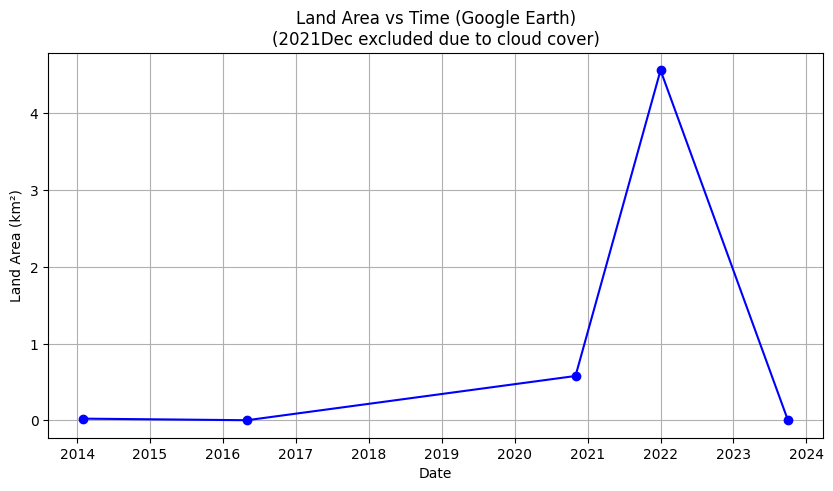

,Date,Land Area (km2)
0,2014-02-01,0.022415
1,2016-05-01,0.001837
2,2020-11-01,0.578387
3,2022-01-01,4.562790
4,2023-10-01,0.001837


In [121]:
df_ge = land_area_time("sentinel-data/White_light")
plot_google_earth(df_ge)
df_ge

### Part 2: Sentinel‑2 Vegetation

In [122]:
def load_band(file_path):
    """
    Load a single band from TIFF file.

    Parameters
    ----------
    file_path : str or Path
        Path to the band file.

    Returns
    -------
    tuple
        (band_array , transform)
    """

    with rasterio.open(file_path) as src:
        return src.read(1).astype(float), src.transform

def calc_ndvi(red, nir):

    """
    Compute NDVI from red and NIR bands.

    Parameters
    ----------
    red : numpy.ndarray
        Red band (B4).
    nir : numpy.ndarray
        Near-infrared band (B8).

    Returns
    -------
    numpy.ndarray
        NDVI array clipped to [0, 1].
    """

    ndvi = (nir - red) / (nir + red)
    ndvi = np.clip(ndvi, 0, 1)
    return ndvi


In [123]:
def veg_area(ndvi, threshold, transform):

    """
    Compute vegetation mask and area using NDVI threshold.

    Parameters
    ----------
    ndvi : numpy.ndarray
        NDVI image.
    threshold : float
        NDVI threshold for vegetation.
    transform : affine.Affine
        transform containing pixel size.

    Returns
    -------
    tuple
        (vegetation mask, vegetation area in km²)
    """

    veg_mask = ndvi > threshold
    veg_pixels = np.sum(veg_mask)

    pixel_width = transform[0]
    pixel_height = -transform[4]
    pixel_area_m2 = pixel_width*pixel_height

    area_km2 = veg_pixels * pixel_area_m2/1e6
    return veg_mask, area_km2

In [124]:
def process_folder(folder, threshold):

    """
    Process a folder to compute NDVI and vegetation area.

    Parameters
    ----------
    folder : Path
        Folder containing bands.
    threshold : float
        NDVI threshold for vegetation.

    Returns
    -------
    tuple
        (date, ndvi array, vegetation mask, vegetation area in km²)
    """

    # loading red (B4) and near infrared (B8) files needed for ndvi
    red_file = folder /"Sentinel-2_L2A_B04_Raw.tiff"
    nir_file = folder /"Sentinel-2_L2A_B08_Raw.tiff"

    red, transform = load_band(red_file)
    nir, _ = load_band(nir_file)

    ndvi = calc_ndvi(red, nir)
    veg_mask, area_km2 = veg_area(ndvi, threshold, transform)

    date = pd.to_datetime(folder.name.replace("S2_", ""))
    return date, ndvi, veg_mask, area_km2

# chosen threshold was trial and error
def veg_time(directory, threshold=0.3):

    """
    Compute vegetation area for all dates.

    Parameters
    ----------
    directory : str or Path
        Root folder
    threshold : float
        NDVI threshold for vegetation.

    Returns
    -------
    pandas.DataFrame
        DataFrame with Date and Vegetation Area (km²).
    """
        
    data_dir = Path(directory)
    dates, areas = [], []

    for folder in sorted(data_dir.glob("S2_*")):
        date, ndvi, veg_mask, area_km2 = process_folder(folder, threshold)
        dates.append(date)
        areas.append(area_km2)

        # plotting vegetation
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(ndvi, cmap="viridis", vmin=-1, vmax=1)
        axes[0].set_title(f"NDVI: {date:%Y-%m-%d}")
        axes[1].imshow(veg_mask, cmap="Greens")
        axes[1].set_title(f"Vegetation (NDVI > {threshold})")
        plt.tight_layout()
        plt.show()

    df = pd.DataFrame({"Date": dates, "Vegetation Area (km²)": areas})
    return df

def plot_sentinel(df):
    plt.figure(figsize=(8,4))
    plt.plot(df["Date"], df["Vegetation Area (km²)"], "o-", color="green")
    plt.title(f"Sentinel-2 Vegetation Area")
    plt.xlabel("Date")
    plt.ylabel("Vegetation Area (km²)")
    plt.grid(True)
    plt.show()


C:\Users\odunu\AppData\Local\Temp\ipykernel_47376\1067827550.py:37: RuntimeWarning: invalid value encountered in divide
  ndvi = (nir - red) / (nir + red)


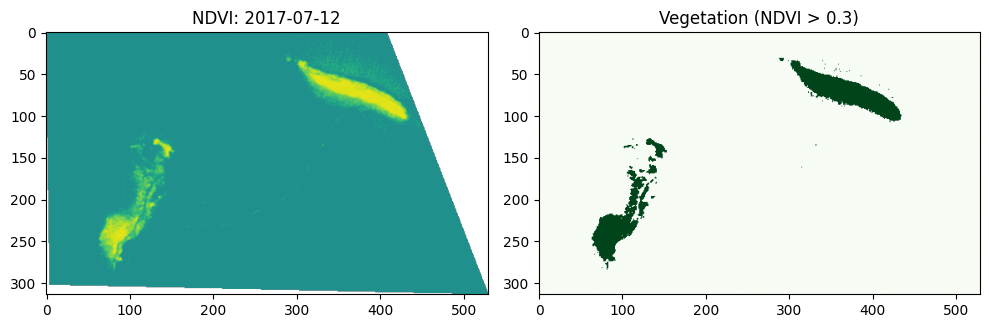

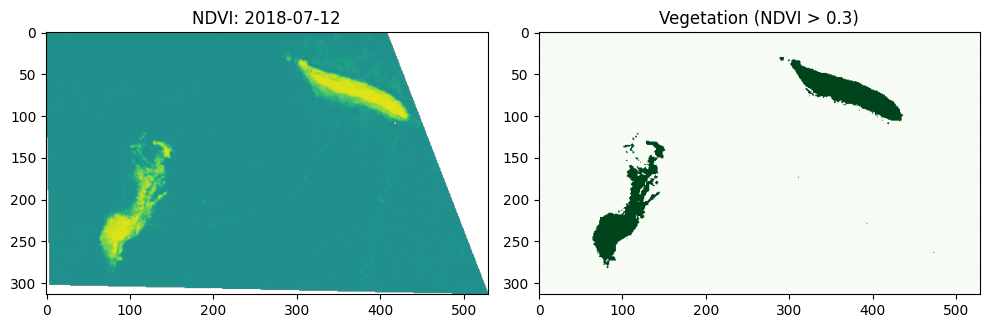

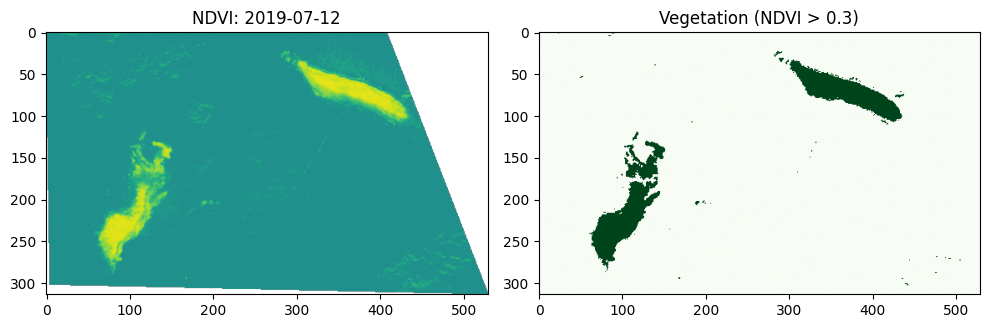

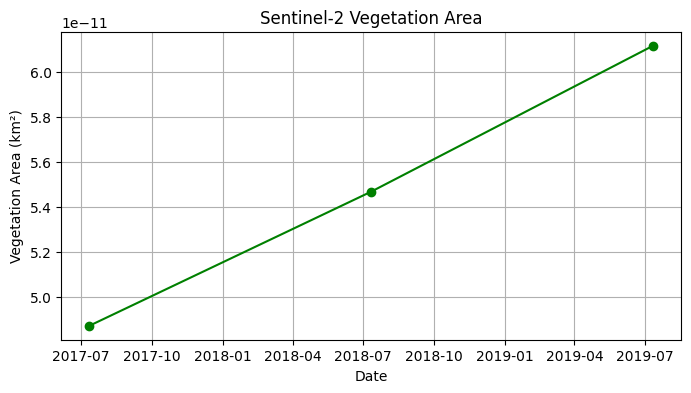

,Date,Vegetation Area (km²)
0,2017-07-12,4.873659e-11
1,2018-07-12,5.468783e-11
2,2019-07-12,6.116083e-11


In [125]:
df_s2 = veg_time("sentinel-data", threshold=0.3)
plot_sentinel(df_s2)
df_s2

### Comparison

C:\Users\odunu\AppData\Local\Temp\ipykernel_47376\2553319913.py:15: RuntimeWarning: invalid value encountered in divide
  ndvi = (nir - red) / (nir + red)


mean diff: -0.7308545321326287
std diff: 0.33090681250563114


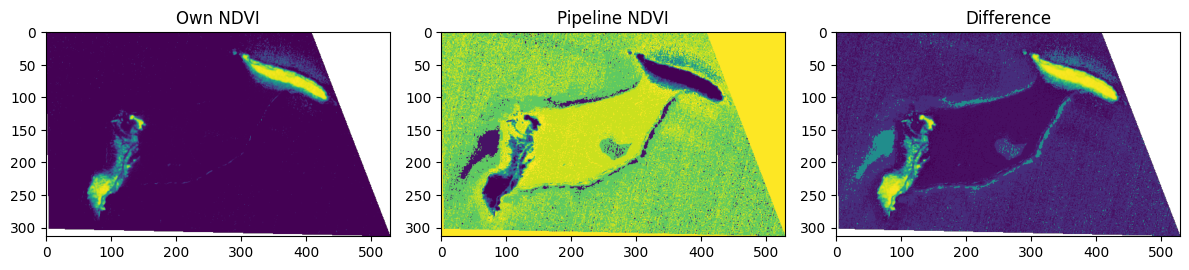

In [131]:
# redining for sake of comparison
def load_band(path):
    with rasterio.open(path) as src:
        return src.read(1).astype(float)

def ndvi_compare(folder):

    """ Compare calculated NDVI with reference NDVI from the pipeline."""
    
    folder = Path(folder)

    # my ndvi calculation
    red = load_band(folder/"Sentinel-2_L2A_B04_Raw.tiff")
    nir = load_band(folder/"Sentinel-2_L2A_B08_Raw.tiff")
    ndvi = (nir - red) / (nir + red)
    ndvi = np.clip(ndvi, 0, 1)  # normalising for comparison

    # refernce NDVI
    ndvi_ref = load_band(folder/"Sentinel-2_L2A_NDVI.tiff")
    if np.nanmax(ndvi_ref) > 1:
        ndvi_ref = ndvi_ref/255

    # difference + stats
    diff = ndvi - ndvi_ref
    print("mean diff:", np.nanmean(diff))
    print("std diff:", np.nanstd(diff))

    # visualing comparison
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    plt.imshow(ndvi, cmap='viridis')
    plt.title("Own NDVI")

    plt.subplot(1,3,2)
    plt.imshow(ndvi_ref, cmap='viridis')
    plt.title("Pipeline NDVI")

    plt.subplot(1,3,3)
    plt.imshow(diff, cmap='viridis')
    plt.title("Difference")
    plt.tight_layout()
    plt.show()

# run
ndvi_compare("sentinel-data/S2_2017-07-12")


The comparison between my own NDVI and the pipeline NDVI shows that both highlight the same main areas of vegetation. The mean difference of −0.73 and standard deviation of 0.33 suggest that the two methods use slightly different scaling or corrections, which causes the offset seen in the difference image. Most of the variation appears along bright vegetated zones and edges, likely due to how the pipeline handles atmospheric and other adjustments. Even with these differences, both versions clearly identify the island’s vegetated regions, showing that the NDVI calculation works well for basic analysis and rough estimates.

## Testing Each Stage Separately (How it progressed) - No Functions

In [127]:
# extracting google earth images
earth_dir = Path("sentinel-data/White_light")
images = sorted(list(earth_dir.glob("*.jpg")))

image = plt.imread(images[0])
print("Image shape:", image.shape)

Image shape: (1992, 2382, 3)


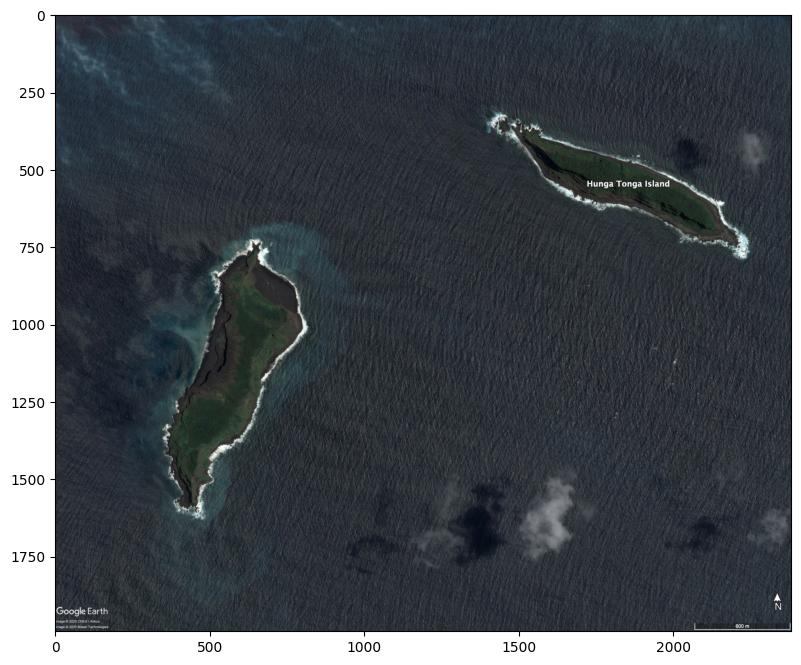

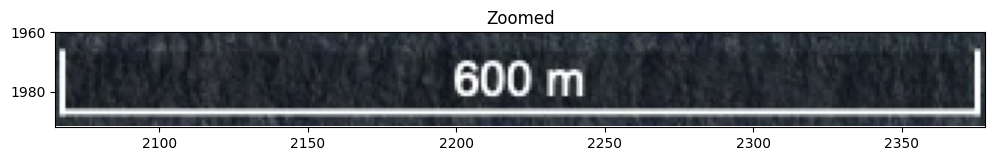

In [128]:
plt.figure(figsize=(12,8))
plt.imshow(image)
plt.show()

### zooming onto scale bar

plt.figure(figsize=(12,8))
plt.imshow(image)
plt.title("Zoomed")
plt.xlim(2065, 2378)   # adjusted to get the no. of pixels (313 -> 600 m)
plt.ylim(1992,1960)
plt.show()

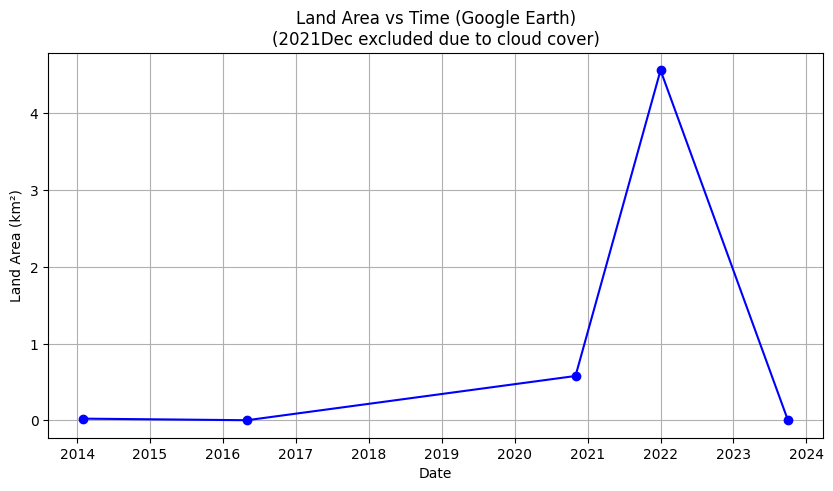

,Date,Land Area (km²)
0,2014-02-01,0.022415
1,2016-05-01,0.001837
2,2020-11-01,0.578387
3,2022-01-01,4.562790
4,2023-10-01,0.001837


In [129]:
images = [img for img in images if "2021Dec" not in img.name]

pixel_size = 600/313

dates, areas_km2 = [], []

for img_path in images:
    date = img_path.stem
    image = plt.imread(img_path)
    gray = np.mean(image, axis=2)# analogue for brightness of pixel

   # assuming land and water will have very different brightness
   # approximate measurement
    mask = gray < 0.5
    land_pixels = np.sum(mask)
    land_area_m2 = land_pixels*(pixel_size**2)

    dates.append(date)
    areas_km2.append(land_area_m2/1e4)

# converting dates so spacing in plot axis is correct
dates_dt = pd.to_datetime(dates, format="%Y%b")

plt.figure(figsize=(10,5))
plt.plot(dates_dt, areas_km2, marker='o', linestyle='-', color='blue')
plt.title("Land Area vs Time (Google Earth)\n(2021Dec excluded due to cloud cover)")
plt.xlabel("Date")
plt.ylabel("Land Area (km²)")
plt.grid(True)
plt.show()

df = pd.DataFrame({"Date": dates_dt, "Land Area (km²)": areas_km2})
df


C:\Users\odunu\AppData\Local\Temp\ipykernel_47376\2901067091.py:20: RuntimeWarning: invalid value encountered in divide
  ndvi = (nir - red)/(nir + red)


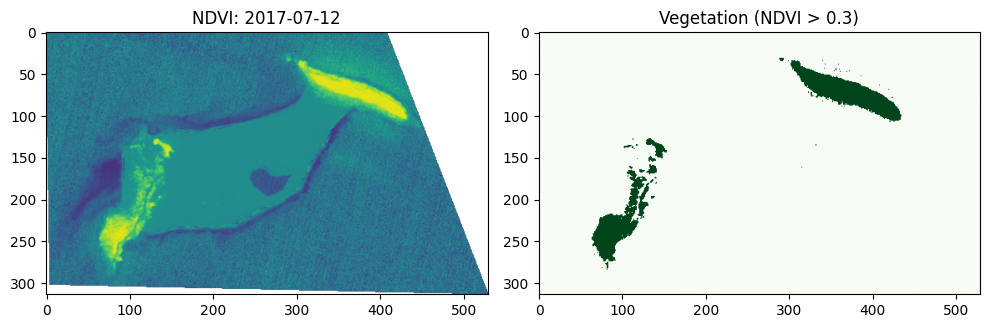

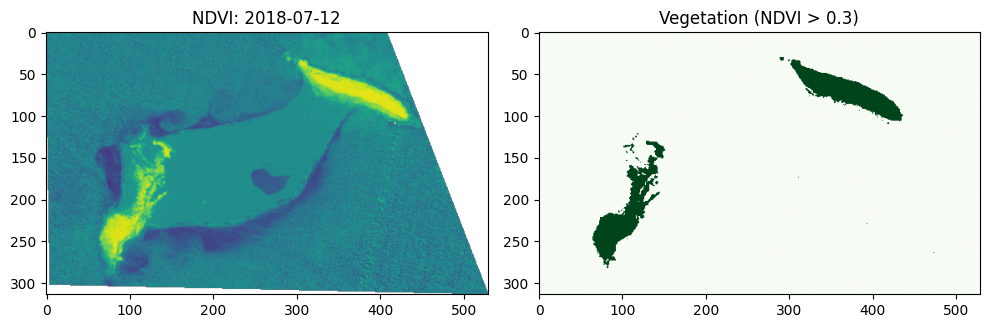

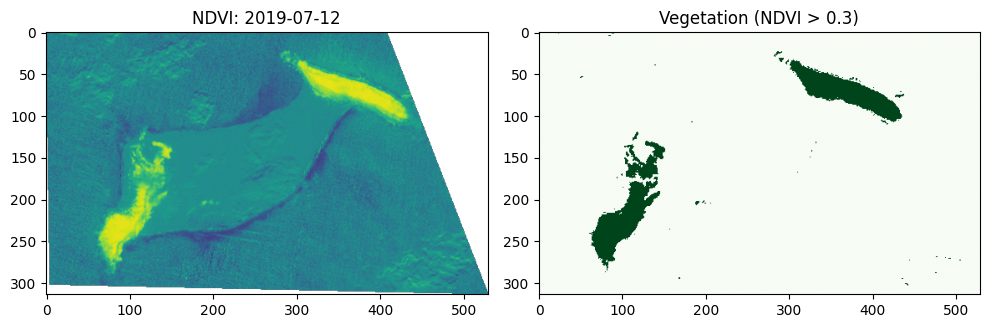

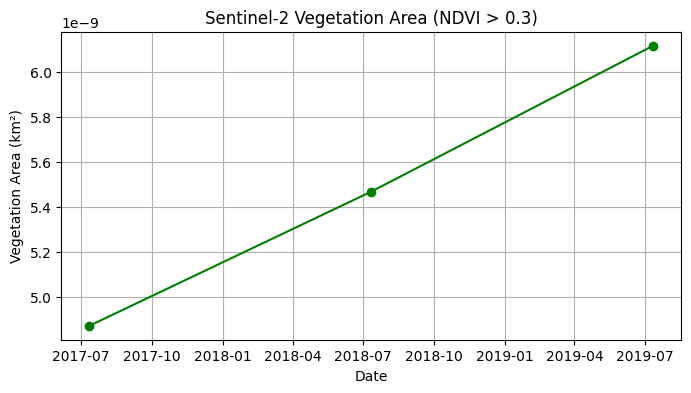

,Date,Vegetation Area (km²)
0,2017-07-12,4.873659e-09
1,2018-07-12,5.468783e-09
2,2019-07-12,6.116083e-09


In [130]:
data_dir = Path("sentinel-data")
threshold = 0.3

dates = []
areas_km2 = []

for folder in sorted(data_dir.glob("S2_*")):
    red_file = folder / "Sentinel-2_L2A_B04_Raw.tiff"
    nir_file = folder / "Sentinel-2_L2A_B08_Raw.tiff"

    # loading red (B4) and near infrared (B8) files needed for ndvi
    with rasterio.open(red_file) as red_src:
        red = red_src.read(1).astype(float)
        transform = red_src.transform

    with rasterio.open(nir_file) as nir_src:
        nir = nir_src.read(1).astype(float)

    # Normalised Difference Vegetation Index (NDVI)
    ndvi = (nir - red)/(nir + red)

    # masking vegetation
    veg_mask = ndvi > threshold
    veg_pixels = np.sum(veg_mask)

    # estimating pixel area from transform
    pixel_width = transform[0]
    pixel_height = -transform[4]
    pixel_area_m2 = pixel_width * pixel_height

    area_km2 = veg_pixels * pixel_area_m2 / 1e4

    # formatting date for analysis
    date = pd.to_datetime(folder.name.replace("S2_", ""))
    dates.append(date)
    areas_km2.append(area_km2)

    # visualisng vegetation
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(ndvi, cmap="viridis", vmin=-1, vmax=1)
    axes[0].set_title(f"NDVI: {date:%Y-%m-%d}")
    axes[1].imshow(veg_mask, cmap="Greens")
    axes[1].set_title(f"Vegetation (NDVI > {threshold})")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(8,4))
plt.plot(dates, areas_km2, "o-", color="green")
plt.title(f"Sentinel-2 Vegetation Area (NDVI > {threshold})")
plt.xlabel("Date")
plt.ylabel("Vegetation Area (km²)")
plt.grid(True)
plt.show()

df = pd.DataFrame({"Date": dates, "Vegetation Area (km²)": areas_km2})
df
